# DistilGPT2 fine-tuning on WikiText-2

**Caroline Meleka | October 2026**

This experiment compares a pretrained language model with short full fine-tuning
runs on WikiText-2. Two learning rates were compared using validation loss. The
selected setting was rerun from the original model and evaluated on a separate
test subset. The executed code and outputs below record the final selected run.

| Model | Validation loss | Validation perplexity | Test loss | Test perplexity |
|---|---:|---:|---:|---:|
| Pretrained | 4.5826 | 97.77 | 4.8446 | 127.05 |
| Fine-tuned, learning rate `5e-5` | 3.8830 | 48.57 | 4.1043 | 60.60 |

The test evaluation contains 8,128 prediction targets. These are small-subset
experiment results, not a full-dataset benchmark or a factual-accuracy score.


## Environment
PyTorch, Transformers and Datasets are used for training and evaluation.
Restart the runtime after installing different package versions, then run the
remaining cells in order. The recorded run used a Tesla T4; exact versions
are included in `environment.txt` and `results.json`.


In [6]:
%pip -q install "torch>=2.6,<3" "transformers==5.20.2" "huggingface-hub>=1.32,<2" "datasets==4.8.5" matplotlib

In [7]:
import gc
import hashlib
import importlib.metadata
import json
import math
import random
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from huggingface_hub import HfApi
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU mode: the later training run will use smaller defaults.')
print('PyTorch:', torch.__version__)
print('Setup complete. Next we will inspect how text becomes tokens.')


Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Setup complete. Next we will inspect how text becomes tokens.


## Model and tokenization
Resolve model and dataset revisions and inspect a tokenized sentence.
The exact revisions used in this run are recorded in `results.json`.


In [8]:
MODEL_ID = 'distilbert/distilgpt2'
DATASET_ID = 'Salesforce/wikitext'
DATASET_CONFIG = 'wikitext-2-raw-v1'

# Resolve exact source revisions and reuse them throughout this run.
api = HfApi()
MODEL_REVISION = api.model_info(MODEL_ID).sha
DATASET_REVISION = api.dataset_info(DATASET_ID).sha
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
tokenizer.pad_token = tokenizer.eos_token

my_sentence = 'I am studying artificial intelligence in Amsterdam.'
token_ids = tokenizer.encode(my_sentence, add_special_tokens=False)
print('My sentence:', my_sentence)
print('Token IDs:', token_ids)
print('Token pieces:', tokenizer.convert_ids_to_tokens(token_ids))
print('Decoded again:', tokenizer.decode(token_ids))
print('Number of tokens:', len(token_ids))


My sentence: I am studying artificial intelligence in Amsterdam.
Token IDs: [40, 716, 11065, 11666, 4430, 287, 24377, 13]
Token pieces: ['I', 'Ġam', 'Ġstudying', 'Ġartificial', 'Ġintelligence', 'Ġin', 'ĠAmsterdam', '.']
Decoded again: I am studying artificial intelligence in Amsterdam.
Number of tokens: 8


## Experiment configuration
The selected run uses seed 42, block size 128, batch size 4, learning rate
`5e-5`, and 100 optimizer updates. CPU defaults use a different, smaller
budget and should not be compared directly with the recorded GPU results.


In [25]:
SEED = 42
BLOCK_SIZE = 128
BATCH_SIZE = 4 if DEVICE.type == 'cuda' else 2
MAX_STEPS = 100 if DEVICE.type == 'cuda' else 24
LEARNING_RATE = 5e-5
TRAIN_BLOCKS = 512 if DEVICE.type == 'cuda' else 128
EVAL_BLOCKS = 64 if DEVICE.type == 'cuda' else 16
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = Path('caroline_lm_runs') / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
set_seed(SEED)

config = dict(model=MODEL_ID, model_revision=MODEL_REVISION,
              dataset=DATASET_ID, dataset_revision=DATASET_REVISION,
              dataset_config=DATASET_CONFIG, seed=SEED, block_size=BLOCK_SIZE,
              batch_size=BATCH_SIZE, max_steps=MAX_STEPS,
              learning_rate=LEARNING_RATE, requested_train_blocks=TRAIN_BLOCKS,
              requested_eval_blocks=EVAL_BLOCKS, device=str(DEVICE))
print(json.dumps(config, indent=2))


{
  "model": "distilbert/distilgpt2",
  "model_revision": "2290a62682d06624634c1f46a6ad5be0f47f38aa",
  "dataset": "Salesforce/wikitext",
  "dataset_revision": "b08601e04326c79dfdd32d625aee71d232d685c3",
  "dataset_config": "wikitext-2-raw-v1",
  "seed": 42,
  "block_size": 128,
  "batch_size": 4,
  "max_steps": 100,
  "learning_rate": 5e-05,
  "requested_train_blocks": 512,
  "requested_eval_blocks": 64,
  "device": "cuda"
}


## Data preparation
Official train, validation and test splits are processed independently.
Nonempty lines are separated by an end-of-text token and packed into
fixed-length blocks. Each block of 128 tokens gives 127 prediction targets.
Deterministic prefixes are used; partial final blocks are discarded.


In [26]:
raw = load_dataset(DATASET_ID, DATASET_CONFIG, revision=DATASET_REVISION)

def pack_split(split, max_rows, max_blocks):
    rows = split.select(range(min(max_rows, len(split))))
    lines = [text.strip() for text in rows['text'] if text.strip()]
    all_ids = []
    for line in lines:
        all_ids.extend(tokenizer.encode(line, add_special_tokens=False))
        all_ids.append(tokenizer.eos_token_id)
        if len(all_ids) >= max_blocks * BLOCK_SIZE:
            break
    used = min(len(all_ids) // BLOCK_SIZE, max_blocks) * BLOCK_SIZE
    if used < BLOCK_SIZE:
        raise ValueError('Not enough text for even one block.')
    packed = torch.tensor(all_ids[:used], dtype=torch.long).reshape(-1, BLOCK_SIZE)
    digest = hashlib.sha256(json.dumps(all_ids[:used]).encode()).hexdigest()
    return packed, dict(blocks=len(packed), tokens=packed.numel(),
                        target_tokens=len(packed) * (BLOCK_SIZE - 1), sha256=digest)

train_blocks, train_info = pack_split(raw['train'], 5000, TRAIN_BLOCKS)
valid_blocks, valid_info = pack_split(raw['validation'], 2000, EVAL_BLOCKS)
# Test is packed now, but its losses will not be computed until the final section.
test_blocks, test_info = pack_split(raw['test'], 2000, EVAL_BLOCKS)
config['actual_data'] = dict(train=train_info, validation=valid_info, test=test_info)

valid_loader = DataLoader(valid_blocks, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_blocks, batch_size=BATCH_SIZE, shuffle=False)
print(json.dumps(config['actual_data'], indent=2))
print('Example training block:\n', tokenizer.decode(train_blocks[0].tolist()))


{
  "train": {
    "blocks": 512,
    "tokens": 65536,
    "target_tokens": 65024,
    "sha256": "75f91c2a62b6b158cef86bd73f4cc8b0ce6ecf8b23581d1cb133245a318e6a97"
  },
  "validation": {
    "blocks": 64,
    "tokens": 8192,
    "target_tokens": 8128,
    "sha256": "be7e595f51a464df51e21d66a22dbbd2ea060530a12e27db674a6d544b92068e"
  },
  "test": {
    "blocks": 64,
    "tokens": 8192,
    "target_tokens": 8128,
    "sha256": "6c409a7e7583ac1a2467025319ec5cf943a324204b6084f75af53c2f62e7606b"
  }
}
Example training block:
 = Valkyria Chronicles III =<|endoftext|>Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as 

## Pretrained baseline
Evaluation uses token-weighted mean next-token loss and its exponential,
perplexity. Unshifted labels are passed to the causal language model, which
shifts them internally. Three fixed prompts use greedy generation for a
consistent qualitative comparison.


In [29]:
def load_original_model():
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, use_safetensors=True
    ).to(DEVICE)
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.use_cache = False
    return model

@torch.no_grad()
def evaluate(model, loader):
    was_training = model.training
    model.eval()
    total_loss, total_targets = 0.0, 0
    try:
        for ids in loader:
            ids = ids.to(DEVICE)
            outputs = model(input_ids=ids, attention_mask=torch.ones_like(ids),
                            labels=ids, use_cache=False)
            n_targets = ids.shape[0] * (ids.shape[1] - 1)
            total_loss += outputs.loss.item() * n_targets
            total_targets += n_targets
    finally:
        model.train(was_training)
    loss = total_loss / total_targets
    if not math.isfinite(loss):
        raise ValueError('Evaluation produced a non-finite loss.')
    return dict(loss=loss, perplexity=math.exp(loss), target_tokens=total_targets)

PROMPTS = ['Amsterdam is a city', 'Artificial intelligence can', 'The history of']

@torch.no_grad()
def generate_samples(model):
    was_training = model.training
    model.eval()
    samples = []
    try:
        for prompt in PROMPTS:
            inputs = tokenizer(prompt, return_tensors='pt').to(DEVICE)
            ids = model.generate(**inputs, max_new_tokens=40, do_sample=False,
                                 pad_token_id=tokenizer.pad_token_id,
                                 eos_token_id=tokenizer.eos_token_id, use_cache=True)
            samples.append(dict(prompt=prompt, text=tokenizer.decode(ids[0], skip_special_tokens=True)))
    finally:
        model.train(was_training)
    return samples

model = load_original_model()
baseline_validation = evaluate(model, valid_loader)
baseline_samples = generate_samples(model)
print('Original validation:', baseline_validation)
for sample in baseline_samples:
    print('\n', sample['text'])


Original validation: {'loss': 4.582642361521721, 'perplexity': 97.77240321654028, 'target_tokens': 8128}

 Amsterdam is a city of over 1,000 people. It is home to the largest city in the world, the Netherlands, and the Netherlands.
















 Artificial intelligence can be used to create a new kind of artificial intelligence.






























 The history of the United States is a fascinating one. The United States is a nation that has been a beacon of hope for the future of the United States.



The United States is a nation that


## Fine-tuning
All model parameters are updated using AdamW, weight decay 0.01 and gradient
clipping at norm 1.0. The run makes 100 updates and processes 50,800 prediction
targets. A sample of weights is compared before and after training.


In [30]:
if globals().get('_trained_run_id') == RUN_ID:
    raise RuntimeError('This experiment has already trained. Restart from section 3 for a fresh run.')
_trained_run_id = RUN_ID
set_seed(SEED)
train_loader = DataLoader(train_blocks, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
tracked_before = next(model.parameters()).detach().flatten()[:64].cpu().clone()
history = []
step = 0
started = time.perf_counter()
model.train()
while step < MAX_STEPS:
    for ids in train_loader:
        ids = ids.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(input_ids=ids, attention_mask=torch.ones_like(ids),
                        labels=ids, use_cache=False)
        loss = outputs.loss
        if not torch.isfinite(loss):
            raise ValueError('Non-finite training loss; stop and inspect the run.')
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        step += 1
        history.append(dict(step=step, loss=float(loss.item()),
                            target_tokens=int(ids.shape[0] * (ids.shape[1] - 1))))
        if step == 1 or step % 10 == 0 or step == MAX_STEPS:
            print(f'Step {step}/{MAX_STEPS}: batch training loss = {loss.item():.4f}')
        if step == MAX_STEPS:
            break
if DEVICE.type == 'cuda':
    torch.cuda.synchronize()
training_seconds = time.perf_counter() - started
tracked_after = next(model.parameters()).detach().flatten()[:64].cpu()
weight_change = float((tracked_after - tracked_before).abs().max())
print('Training seconds:', round(training_seconds, 1))
print('Largest change in 64 tracked weights:', weight_change)
print('Training target tokens processed (including repeats):', sum(x['target_tokens'] for x in history))


Step 1/100: batch training loss = 4.7529
Step 10/100: batch training loss = 4.3304
Step 20/100: batch training loss = 4.0686
Step 30/100: batch training loss = 4.2764
Step 40/100: batch training loss = 4.2799
Step 50/100: batch training loss = 4.2019
Step 60/100: batch training loss = 4.2869
Step 70/100: batch training loss = 3.7775
Step 80/100: batch training loss = 3.8649
Step 90/100: batch training loss = 4.0691
Step 100/100: batch training loss = 4.0616
Training seconds: 13.7
Largest change in 64 tracked weights: 0.0033236443996429443
Training target tokens processed (including repeats): 50800


## Validation and generation analysis
The fine-tuned model is evaluated on the same validation subset as the
pretrained baseline. The plot shows individual training-batch losses and
aggregate validation losses; generated samples are inspected separately.


Original validation: {'loss': 4.582642361521721, 'perplexity': 97.77240321654028, 'target_tokens': 8128}
Fine-tuned validation: {'loss': 3.8830473124980927, 'perplexity': 48.57200385207645, 'target_tokens': 8128}
Validation loss change (negative is better): -0.6995950490236282


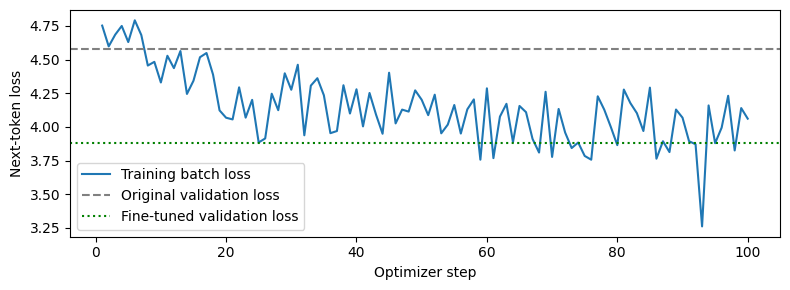


PROMPT: Amsterdam is a city
ORIGINAL: Amsterdam is a city of over 1,000 people. It is home to the largest city in the world, the Netherlands, and the Netherlands.















FINE-TUNED: Amsterdam is a city of over 1 million people . The city is home to the largest concentration of illegal drugs in the world . The city is home to the largest concentration of illegal drugs in the world . The city is home

PROMPT: Artificial intelligence can
ORIGINAL: Artificial intelligence can be used to create a new kind of artificial intelligence.





























FINE-TUNED: Artificial intelligence can be used to create a new kind of human being , and the human being can be used to create a new kind of human being , and the human being can be used to create a new kind of

PROMPT: The history of
ORIGINAL: The history of the United States is a fascinating one. The United States is a nation that has been a beacon of hope for the future of the United States.



The United States is a nat

In [31]:
trained_validation = evaluate(model, valid_loader)
trained_samples = generate_samples(model)
print('Original validation:', baseline_validation)
print('Fine-tuned validation:', trained_validation)
print('Validation loss change (negative is better):',
      trained_validation['loss'] - baseline_validation['loss'])
validation_record = dict(config=config, completed_steps=step,
                         baseline_validation=baseline_validation,
                         trained_validation=trained_validation,
                         history=history, baseline_samples=baseline_samples,
                         trained_samples=trained_samples)
(RUN_DIR / 'validation_results.json').write_text(
    json.dumps(validation_record, indent=2), encoding='utf-8')

plt.figure(figsize=(8, 3))
plt.plot([x['step'] for x in history], [x['loss'] for x in history], label='Training batch loss')
plt.axhline(baseline_validation['loss'], color='gray', linestyle='--', label='Original validation loss')
plt.axhline(trained_validation['loss'], color='green', linestyle=':', label='Fine-tuned validation loss')
plt.xlabel('Optimizer step')
plt.ylabel('Next-token loss')
plt.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / 'loss_curve.png', dpi=150)
plt.show()
for before, after in zip(baseline_samples, trained_samples):
    print('\nPROMPT:', before['prompt'])
    print('ORIGINAL:', before['text'])
    print('FINE-TUNED:', after['text'])


## Final test and model export
The test split is evaluated after the learning rate has been selected using
validation. The selected model, tokenizer, metrics, generations, configuration
and environment versions are saved together. The executed code below records
that final test, rather than a further tuning step.


In [33]:
READY_FOR_FINAL_TEST = True  # Change this only once your validation-based choice is final.
if not READY_FOR_FINAL_TEST:
    raise RuntimeError('Discuss your validation results first, then enable the final test.')
if (RUN_DIR / 'results.json').exists():
    raise RuntimeError('This run already has final results; inspect the saved file instead.')
if step != MAX_STEPS:
    raise RuntimeError('Training was interrupted. Start a fresh complete run before final testing.')

# Release optimizer state before loading a second copy for the original baseline.
globals().pop('optimizer', None)
gc.collect()
model.to('cpu')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
original_model = load_original_model()
baseline_test = evaluate(original_model, test_loader)
del original_model
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
model.to(DEVICE)
trained_test = evaluate(model, test_loader)
versions = {name: importlib.metadata.version(name) for name in
            ['torch', 'transformers', 'datasets', 'huggingface-hub', 'matplotlib']}
results = dict(config=config, versions=versions, python=sys.version,
               gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
               baseline_validation=baseline_validation, trained_validation=trained_validation,
               baseline_test=baseline_test, trained_test=trained_test,
               completed_steps=step, training_seconds=training_seconds,
               tracked_weight_max_change=weight_change,
               processed_training_target_tokens=sum(x['target_tokens'] for x in history),
               history=history, baseline_samples=baseline_samples, trained_samples=trained_samples)
model.save_pretrained(RUN_DIR / 'model', safe_serialization=True)
tokenizer.save_pretrained(RUN_DIR / 'model')
(RUN_DIR / 'results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
(RUN_DIR / 'environment.txt').write_text(
    '\n'.join(f'{name}=={version}' for name, version in versions.items()), encoding='utf-8')
print('Original test:', baseline_test)
print('Fine-tuned test:', trained_test)
print('Saved run to:', RUN_DIR.resolve())


Original test: {'loss': 4.844583123922348, 'perplexity': 127.05030671891225, 'target_tokens': 8128}
Fine-tuned test: {'loss': 4.104254066944122, 'perplexity': 60.597525986955056, 'target_tokens': 8128}
Saved run to: /content/caroline_lm_runs/20261027T205023279057Z


## Learning-rate comparison

| Learning rate | Validation loss | Validation perplexity |
|---|---:|---:|
| `5e-5` | 3.8830 | 48.57 |
| `2e-5` | 3.9169 | 50.25 |

Both trials used the same seed, data preparation, batch size and 100-step budget.
`5e-5` had the lower validation loss and was selected for the final test. The
retained notebook and archive contain that selected run; the `2e-5` row was
recorded during the earlier experiment and is not a second archived checkpoint.

## Findings and limitations

- Test perplexity fell from 127.05 to 60.60, a 52.30% reduction under this protocol.
- Generated text still contained repetition and fabricated claims, including
  incorrect historical statements in the United States completion.
- Lower next-token loss did not establish factual reliability or production quality.
- The experiment uses small deterministic subsets, one seed and a short budget.
  Statistical significance was not assessed.
- Evaluation text was held out from this fine-tuning run. Possible overlap with
  the model's original pretraining data was not assessed.

A follow-up would repeat the comparison across seeds and evaluate a concrete
downstream task with explicit correctness criteria.

## References

- [DistilGPT2 model card](https://huggingface.co/distilbert/distilgpt2)
- [WikiText dataset card](https://huggingface.co/datasets/Salesforce/wikitext)
- [Hugging Face causal language modeling](https://huggingface.co/docs/transformers/tasks/language_modeling)
- [PyTorch optimization tutorial](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
